# ML CIE 2 – Activity 1
## Dataset Preparation and Exploratory Data Analysis

**Subject:** Machine Learning

**Dataset:** Hotel Booking Demand Dataset

**Objective:**

To perform data preparation on a real-world dataset by inspecting the data, handling missing values and duplicate records, performing Exploratory Data Analysis (EDA), encoding categorical features, scaling numerical features, and exporting the prepared dataset.

##Import libiaries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


**Dataset Name:** Hotel Booking Demand Dataset

**Source:** [Kaggle – Hotel Booking Demand Dataset](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)

**Description:**

This dataset contains hotel booking information for a city hotel and a resort hotel. It includes details about booking dates, guest information, length of stay, room types, booking channels, prices, and cancellations.

**Purpose:**

The dataset will be used to understand and prepare real-world data containing both numerical and categorical features. It also contains missing values, making it suitable for practicing data cleaning and preprocessing.

##Load dataset

In [2]:
df = pd.read_csv('/content/hotel_bookings.csv')
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("First 5 Records:")
display(df.head())

print("\nLast 5 Records:")
display(df.tail())

print("\nDataset Shape:", df.shape)

First 5 Records:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



Last 5 Records:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07



Dataset Shape: (119390, 32)


In [4]:
# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types
print("\nColumn Data Types:")
print(df.dtypes)

# Dataset information
print("\nDataset Information:")
df.info()


Column Names:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']

Column Data Types:
hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_w

In [5]:
# Separate numerical and categorical columns

numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns
categorical_columns = df.select_dtypes(include=['object']).columns

print("Numerical Columns:")
print(list(numerical_columns))
print("\nTotal Numerical Columns:", len(numerical_columns))

print("\nCategorical Columns:")
print(list(categorical_columns))
print("\nTotal Categorical Columns:", len(categorical_columns))

Numerical Columns:
['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Total Numerical Columns: 20

Categorical Columns:
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']

Total Categorical Columns: 12


## Check missing values

In [6]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values[missing_values > 0])

print("\nTotal Missing Values:", missing_values.sum())

Missing Values in Each Column:
children         4
country        488
agent        16340
company     112593
dtype: int64

Total Missing Values: 129425


In [7]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [8]:
for column in categorical_columns:
    print("\nFrequency of", column)
    print(df[column].value_counts().head(10))


Frequency of hotel
hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64

Frequency of arrival_date_month
arrival_date_month
August       13877
July         12661
May          11791
October      11160
April        11089
June         10939
September    10508
March         9794
February      8068
November      6794
Name: count, dtype: int64

Frequency of meal
meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64

Frequency of country
country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
ITA     3766
IRL     3375
BEL     2342
BRA     2224
NLD     2104
Name: count, dtype: int64

Frequency of market_segment
market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64

Frequency of distribution_channel
distribution_cha

After inspecting the dataset, the following observations were made:

1. The dataset contains 119,390 records and 32 columns.
2. It consists of 20 numerical columns and 12 categorical columns.
3. Missing values are present in children, country, agent, and company.
4. City Hotel has more bookings than Resort Hotel.
5. BB (Bed & Breakfast) is the most frequently selected meal plan.
6. Portugal (PRT) is the most frequently recorded country.
7. Online TA is the most common market segment.
8. The average daily room rate (ADR) is approximately 101.83.

The column `is_canceled` can be considered as a target variable for a possible hotel booking cancellation prediction task.

In [9]:
#backup of the original dataset
df_original = df.copy()

#separate working copy for data cleaning
df_clean = df.copy()

print("Original dataset shape:", df_original.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (119390, 32)
Working dataset shape: (119390, 32)


## Handle missing values

In [10]:
# Fill missing children values with the median
df_clean['children'] = df_clean['children'].fillna(df_clean['children'].median())

# Fill missing country values with the mode
df_clean['country'] = df_clean['country'].fillna(df_clean['country'].mode()[0])

# Create indicators for missing agent and company information
df_clean['has_agent'] = df_clean['agent'].notna().astype(int)
df_clean['has_company'] = df_clean['company'].notna().astype(int)

# Drop agent and company columns due to excessive missing values
df_clean.drop(columns=['agent', 'company'], inplace=True)

print("Missing values handled successfully!")
print("\nRemaining missing values:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

print("\nUpdated dataset shape:", df_clean.shape)

Missing values handled successfully!

Remaining missing values:
Series([], dtype: int64)

Updated dataset shape: (119390, 32)


In [11]:
# Verify
print("Total missing values:", df_clean.isnull().sum().sum())

print("\nMissing values in each column:")
print(df_clean.isnull().sum())

Total missing values: 0

Missing values in each column:
hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
days_in_waiting_list              0
customer_type                     0
adr                               0
required

## Check duplicate values
#### Duplicate records can affect analysis by counting the same booking more than once

In [12]:
duplicate_count = df_clean.duplicated().sum()
print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 32030


#### Remove duplicates

In [13]:
df_clean.drop_duplicates(inplace=True)
print("Duplicate records removed successfully!")
print("Remaining duplicate records:", df_clean.duplicated().sum())
print("Updated dataset shape:", df_clean.shape)

Duplicate records removed successfully!
Remaining duplicate records: 0
Updated dataset shape: (87360, 32)


In [14]:
# Check unique values in categorical columns

categorical_columns_clean = df_clean.select_dtypes(include=['object']).columns
for column in categorical_columns_clean:
    print("\nColumn:", column)
    print("Unique values:", df_clean[column].nunique())
    print(df_clean[column].unique()[:20])


Column: hotel
Unique values: 2
['Resort Hotel' 'City Hotel']

Column: arrival_date_month
Unique values: 12
['July' 'August' 'September' 'October' 'November' 'December' 'January'
 'February' 'March' 'April' 'May' 'June']

Column: meal
Unique values: 5
['BB' 'FB' 'HB' 'SC' 'Undefined']

Column: country
Unique values: 177
['PRT' 'GBR' 'USA' 'ESP' 'IRL' 'FRA' 'ROU' 'NOR' 'OMN' 'ARG' 'POL' 'DEU'
 'BEL' 'CHE' 'CN' 'GRC' 'ITA' 'NLD' 'DNK' 'RUS']

Column: market_segment
Unique values: 8
['Direct' 'Corporate' 'Online TA' 'Offline TA/TO' 'Complementary' 'Groups'
 'Undefined' 'Aviation']

Column: distribution_channel
Unique values: 5
['Direct' 'Corporate' 'TA/TO' 'Undefined' 'GDS']

Column: reserved_room_type
Unique values: 10
['C' 'A' 'D' 'E' 'G' 'F' 'H' 'L' 'P' 'B']

Column: assigned_room_type
Unique values: 12
['C' 'A' 'D' 'E' 'G' 'F' 'I' 'B' 'H' 'P' 'L' 'K']

Column: deposit_type
Unique values: 3
['No Deposit' 'Refundable' 'Non Refund']

Column: customer_type
Unique values: 4
['Transient' 'C

#### Visualizing

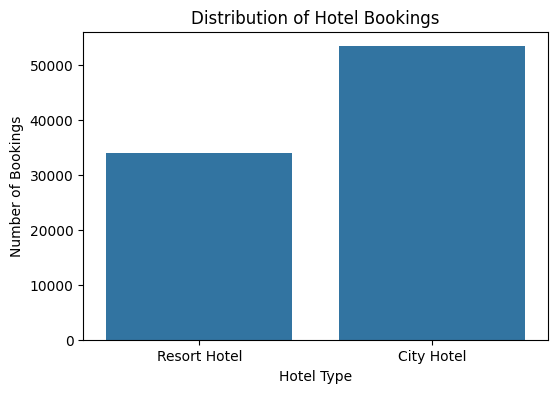

In [15]:
plt.figure(figsize=(6,4))
sns.countplot(data=df_clean, x='hotel')
plt.title('Distribution of Hotel Bookings')
plt.xlabel('Hotel Type')
plt.ylabel('Number of Bookings')
plt.show()

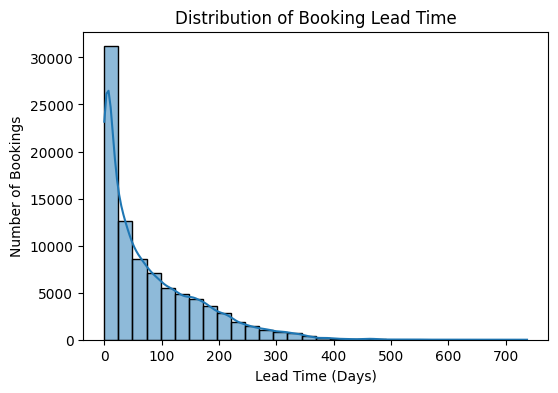

In [16]:
plt.figure(figsize=(6,4))
sns.histplot(data=df_clean, x='lead_time', bins=30, kde=True)
plt.title('Distribution of Booking Lead Time')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Number of Bookings')
plt.show()

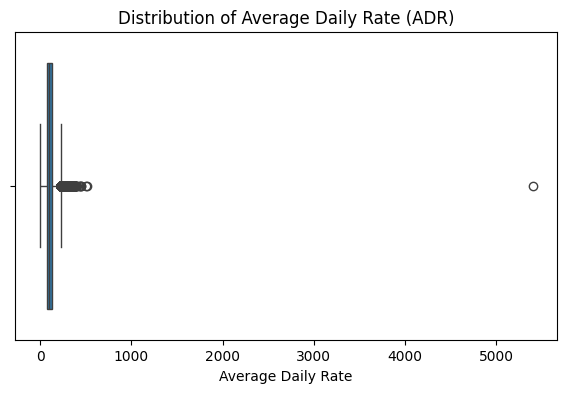

In [17]:
plt.figure(figsize=(7,4))
sns.boxplot(data=df_clean, x='adr')
plt.title('Distribution of Average Daily Rate (ADR)')
plt.xlabel('Average Daily Rate')
plt.show()

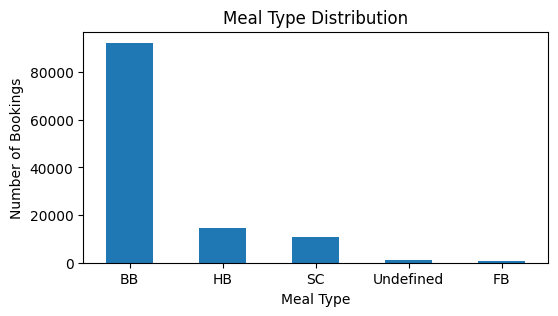

In [18]:
plt.figure(figsize=(6,3))
df_original['meal'].value_counts().plot(kind='bar')
plt.title('Meal Type Distribution')
plt.xlabel('Meal Type')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=0)
plt.show()

In [19]:
# Remove columns
df_clean.drop(
    columns=['reservation_status', 'reservation_status_date'],
    inplace=True
)

print("Unnecessary target-related columns removed.")
print("\nUpdated dataset shape:", df_clean.shape)
print("\nRemaining columns:")
print(df_clean.columns.tolist())

Unnecessary target-related columns removed.

Updated dataset shape: (87360, 30)

Remaining columns:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'has_agent', 'has_company']


## Encoding Categorical Features

Encoding is the process of converting categorical data into numerical values so that machine learning algorithms can process it.

1. **Label Encoding:** Converts categories into numerical values. We use a predefined mapping to convert arrival month names into numbers from 1 to 12.
2. **One-Hot Encoding:** Creates separate binary columns for categories. It is suitable for nominal categorical features where categories do not have a natural order.

The arrival month column is converted into numerical values using a predefined mapping.

In [20]:
month_mapping = {
    'January': 1,
    'February': 2,
    'March': 3,
    'April': 4,
    'May': 5,
    'June': 6,
    'July': 7,
    'August': 8,
    'September': 9,
    'October': 10,
    'November': 11,
    'December': 12
}

df_clean['arrival_date_month'] = df_clean['arrival_date_month'].map(month_mapping)

print("Month encoding completed!")
print(df_clean['arrival_date_month'].unique())

Month encoding completed!
[ 7  8  9 10 11 12  1  2  3  4  5  6]


####
The country column contains 177 unique categories. Creating a separate column for every country would produce too many features, keep the 10 most frequent countries and group all remaining countries into Other.

In [21]:
top_countries = df_clean['country'].value_counts().head(10).index

df_clean['country'] = df_clean['country'].apply(
    lambda x: x if x in top_countries else 'Other'
)

print("Country grouping completed!")
print("\nCountry frequency:")
print(df_clean['country'].value_counts())

Country grouping completed!

Country frequency:
country
PRT      27875
Other    15512
GBR      10432
FRA       8837
ESP       7251
DEU       5385
ITA       3066
IRL       3016
BEL       2081
BRA       1994
NLD       1911
Name: count, dtype: int64


In [22]:
# Identifying categorical columns
categorical_cols = df_clean.select_dtypes(include=['object']).columns

# One-Hot Encoding
df_clean = pd.get_dummies(
    df_clean,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)
print("One-Hot Encoding completed!")
print("\nUpdated dataset shape:", df_clean.shape)
print("\nFirst 5 records:")
display(df_clean.head())

One-Hot Encoding completed!

Updated dataset shape: (87360, 72)

First 5 records:


,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,...,assigned_room_type_H,assigned_room_type_I,assigned_room_type_K,assigned_room_type_L,assigned_room_type_P,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Group,customer_type_Transient,customer_type_Transient-Party
0,0,342,2015,7,27,1,0,0,2,0.0,...,0,0,0,0,0,0,0,0,1,0
1,0,737,2015,7,27,1,0,0,2,0.0,...,0,0,0,0,0,0,0,0,1,0
2,0,7,2015,7,27,1,0,1,1,0.0,...,0,0,0,0,0,0,0,0,1,0
3,0,13,2015,7,27,1,0,1,1,0.0,...,0,0,0,0,0,0,0,0,1,0
4,0,14,2015,7,27,1,0,2,2,0.0,...,0,0,0,0,0,0,0,0,1,0


In [23]:
print("Missing month values:", df_clean['arrival_date_month'].isnull().sum())

print("\nMonth column data type:")
print(df_clean['arrival_date_month'].dtype)

print("\nOriginal month values:")
print(df_original['arrival_date_month'].value_counts())

Missing month values: 0

Month column data type:
int64

Original month values:
arrival_date_month
August       13877
July         12661
May          11791
October      11160
April        11089
June         10939
September    10508
March         9794
February      8068
November      6794
December      6780
January       5929
Name: count, dtype: int64


In [24]:
# Restore month names from the original dataset
df_clean['arrival_date_month'] = df_original.loc[
    df_clean.index, 'arrival_date_month'
]

# Convert month names into numbers
month_mapping = {
    'January': 1, 'February': 2, 'March': 3,
    'April': 4, 'May': 5, 'June': 6,
    'July': 7, 'August': 8, 'September': 9,
    'October': 10, 'November': 11, 'December': 12
}

df_clean['arrival_date_month'] = df_clean['arrival_date_month'].map(month_mapping)

print("Month encoding fixed!")
print("\nMissing values:", df_clean['arrival_date_month'].isnull().sum())
print("\nMonth values:")
print(sorted(df_clean['arrival_date_month'].unique()))

Month encoding fixed!

Missing values: 0

Month values:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]


## Feature scaling

In [25]:
scaling_columns = [
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'babies',
    'previous_cancellations',
    'previous_bookings_not_canceled',
    'booking_changes',
    'days_in_waiting_list',
    'adr',
    'total_of_special_requests'
]
print("Features selected for scaling:")
print(scaling_columns)
print("\nTotal features:", len(scaling_columns))

Features selected for scaling:
['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'total_of_special_requests']

Total features: 12


## Feature Scaling

Feature scaling is the process of transforming numerical features into a common scale so that features with larger values do not dominate those with smaller values.

**Standardization (Standard Scaling)** is applied using the `StandardScaler` function from Scikit-learn.

**Formula:**

\[
Z = \frac{X-\mu}{\sigma}
\]

Where:
- \(X\) = Original value
- \(\mu\) = Mean of the feature
- \(\sigma\) = Standard deviation of the feature

After scaling, the mean of each feature becomes approximately 0 and its standard deviation becomes approximately 1.

In [26]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

# Apply scaling
df_clean[scaling_columns] = scaler.fit_transform(df_clean[scaling_columns])
print("Standard Scaling completed!")

display(df_clean[scaling_columns].head())

Standard Scaling completed!


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,adr,total_of_special_requests
0,3.045586,-0.9743,-1.278504,0.198006,-0.304176,-0.095189,-0.082406,-0.106259,3.750959,-0.074855,-1.933449,-0.839803
1,7.635599,-0.9743,-1.278504,0.198006,-0.304176,-0.095189,-0.082406,-0.106259,5.125789,-0.074855,-1.933449,-0.839803
2,-0.847210,-0.9743,-0.791588,-1.398171,-0.304176,-0.095189,-0.082406,-0.106259,-0.373530,-0.074855,-0.569964,-0.839803
3,-0.777488,-0.9743,-0.791588,-1.398171,-0.304176,-0.095189,-0.082406,-0.106259,-0.373530,-0.074855,-0.569964,-0.839803
4,-0.765868,-0.9743,-0.304673,0.198006,-0.304176,-0.095189,-0.082406,-0.106259,-0.373530,-0.074855,-0.151828,0.362156


In [27]:
print("Mean after scaling:")
print(df_clean[scaling_columns].mean().round(2))

print("\nStandard deviation after scaling:")
print(df_clean[scaling_columns].std().round(2))

Mean after scaling:
lead_time                        -0.0
stays_in_weekend_nights          -0.0
stays_in_week_nights             -0.0
adults                            0.0
children                          0.0
babies                           -0.0
previous_cancellations            0.0
previous_bookings_not_canceled    0.0
booking_changes                   0.0
days_in_waiting_list              0.0
adr                              -0.0
total_of_special_requests        -0.0
dtype: float64

Standard deviation after scaling:
lead_time                         1.0
stays_in_weekend_nights           1.0
stays_in_week_nights              1.0
adults                            1.0
children                          1.0
babies                            1.0
previous_cancellations            1.0
previous_bookings_not_canceled    1.0
booking_changes                   1.0
days_in_waiting_list              1.0
adr                               1.0
total_of_special_requests         1.0
dtype: float64


In [28]:
print("Final Dataset Shape:", df_clean.shape)

print("\nTotal Missing Values:", df_clean.isnull().sum().sum())

print("\nTotal Duplicate Records:", df_clean.duplicated().sum())

print("\nRemaining Categorical Columns:")
print(df_clean.select_dtypes(include=['object']).columns.tolist())

print("\nFirst 5 Rows:")
display(df_clean.head())

Final Dataset Shape: (87360, 72)

Total Missing Values: 0

Total Duplicate Records: 489

Remaining Categorical Columns:
[]

First 5 Rows:


,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,...,assigned_room_type_H,assigned_room_type_I,assigned_room_type_K,assigned_room_type_L,assigned_room_type_P,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Group,customer_type_Transient,customer_type_Transient-Party
0,0,3.045586,2015,7,27,1,-0.9743,-1.278504,0.198006,-0.304176,...,0,0,0,0,0,0,0,0,1,0
1,0,7.635599,2015,7,27,1,-0.9743,-1.278504,0.198006,-0.304176,...,0,0,0,0,0,0,0,0,1,0
2,0,-0.847210,2015,7,27,1,-0.9743,-0.791588,-1.398171,-0.304176,...,0,0,0,0,0,0,0,0,1,0
3,0,-0.777488,2015,7,27,1,-0.9743,-0.791588,-1.398171,-0.304176,...,0,0,0,0,0,0,0,0,1,0
4,0,-0.765868,2015,7,27,1,-0.9743,-0.304673,0.198006,-0.304176,...,0,0,0,0,0,0,0,0,1,0


In [29]:
df_clean.drop_duplicates(inplace=True)

print("Duplicate records removed!")
print("\nFinal Dataset Shape:", df_clean.shape)
print("Remaining Duplicates:", df_clean.duplicated().sum())
print("Missing Values:", df_clean.isnull().sum().sum())

Duplicate records removed!

Final Dataset Shape: (86871, 72)
Remaining Duplicates: 0
Missing Values: 0


## Final Data Cleaning and Verification

After encoding and scaling, the dataset is checked again for duplicate records and missing values.

Duplicate records are removed to avoid repeated observations and maintain data quality.

The final dataset is then verified to ensure:
- No missing values remain.
- No duplicate records remain.
- All categorical features have been converted into numerical form.
- The dataset is ready for further machine learning tasks.

In [30]:
# Saving the final prepared dataset as a CSV file
df_clean.to_csv('hotel_bookings_prepared.csv', index=False)

print("Prepared dataset saved successfully!")

Prepared dataset saved successfully!


In [31]:
from google.colab import files

files.download('hotel_bookings_prepared.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
# Save prepared dataset in compressed format
df_clean.to_csv(
    'hotel_bookings_prepared.csv.gz',
    index=False,
    compression='gzip'
)

print("Compressed dataset created successfully!")

Compressed dataset created successfully!


In [33]:
from google.colab import files

files.download('hotel_bookings_prepared.csv.gz')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

In this activity, the Hotel Booking Demand dataset was successfully prepared using Python libraries such as Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn.

The following operations were performed:

1. Loaded and inspected the dataset.
2. Identified numerical and categorical features.
3. Handled missing values.
4. Detected and removed duplicate records.
5. Inspected categorical values for consistency.
6. Performed Exploratory Data Analysis (EDA) using visualizations.
7. Applied One-Hot Encoding and numerical mapping to categorical features.
8. Applied Standard Scaling to selected numerical features.
9. Verified and saved the final prepared dataset as a CSV file.

**Final Dataset:** 86,871 rows and 72 columns, with no missing values or duplicate records.

The activity helped in understanding the importance of data cleaning, preprocessing, and EDA before applying machine learning algorithms.